# Estudo Comparativo de Classificação Acústica Submarina — Dataset IARA
### Notebook 9: Comparativo Multimodelo com o Extrator DEMON (SVM, Random Forest, MLP e CNN)

Neste notebook, investigamos o comportamento do extrator **DEMON** (*Demodulation of Envelope Modulation on Noise*) puro ($0{,}39\text{ Hz}$ a $25\text{ Hz}$) através de **quatro famílias de aprendizado de máquina**:

1. **SVM Nyström ($m=1000, 4000, 6000$):** núcleo RBF aproximado por *landmark points* com penalidade ElasticNet (`max_iter=1000`, sem early stopping).
2. **Random Forest (100 árvores):** ensemble de árvores com `class_weight='balanced'`.
3. **Multi-Layer Perceptron (MLP PyTorch `[32, 16]`):** rede feedforward com `BatchNorm1d` e `Dropout 0.2`.
4. **CNN 2D ad hoc (PyTorch):** convoluções 2D sobre blocos de 32 vetores DEMON consecutivos ($32 \times 253$).
5. **Duas CNNs 1D novas (seção 6.2):** a **CNN espectral** desenhada para a HHT (`iara.ml.models.spectral_cnn.SpectralCNN`), aplicada ao DEMON sem mudanças de arquitetura, e a **CNN harmônica** feita para o DEMON (`iara.ml.models.harmonic_cnn.HarmonicCNN`: normalização TPSW pelo fundo e empilhamento harmônico $X(h \cdot f_0)$, $h = 0{,}5, 1, \dots, 5$), com 1 janela ou com a mediana de 5 janelas vizinhas.

Todos os modelos foram avaliados sob o protocolo oficial de **$5\times2$ validação cruzada (10 folds)** com **particionamento por gravação de áudio (`ID`, `exclusive_header='ID'` em `src/iara/ml/experiment.py`)** — janelas de um mesmo arquivo nunca ficam em treino e teste ao mesmo tempo — sobre os **1.706 áudios de UO** do IARA (*Silva et al.*, IEEE Access 2025). O particionamento **não** isola navios: gravações diferentes do mesmo navio (`Ship ID`) podem cair em treino e teste.

> Todos os números são recalculados das predições por janela em `results/trainings/` por `notebooks/iara_results.py` (voto majoritário por arquivo, SP de `src/iara/ml/metrics.py`, **ACC = acurácia balanceada**, média ± desvio populacional nos 10 folds).

In [1]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
try:
    from IPython.display import display
except ImportError:
    display = print

for _p in ('.', 'src', 'notebooks', 'notebooks/src'):
    if os.path.exists(os.path.join(_p, 'iara_results.py')) and os.path.abspath(_p) not in sys.path:
        sys.path.insert(0, os.path.abspath(_p))
import iara_results as R

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams.update({'font.family': 'sans-serif', 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 13,
                     'xtick.labelsize': 10, 'ytick.labelsize': 10, 'figure.titlesize': 15, 'figure.dpi': 120})

## 1. Tabela Mestra: DEMON vs. Referências MEL/LOFAR

> **Notas metodológicas:**
> * **ACC = acurácia balanceada** (média dos recalls) em todas as tabelas, inclusive na Tabela 7 do artigo. Versões anteriores deste notebook misturavam acurácia micro (UACC) e balanceada na mesma coluna.
> * **Três modos, sempre rotulados:** `4c` (4 classes); `4c_sem_bg` (o mesmo modelo 4c avaliado só em navios, prever BACKGROUND = erro; os recalls por classe são os mesmos do 4c); `3c` (modelo **retreinado** sem BACKGROUND — só existe para o DEMON). Comparações entre DEMON e MEL/LOFAR "em 3 classes" só são válidas no modo `4c_sem_bg`.
> * **Referências locais MEL/LOFAR** vêm do pipeline iara oficial (`results/trainings/tests`, janelas de 0,512 s); o DEMON usa um vetor a cada 5,12 s. O recall de `SMALL` do `SVM m=6000 | LOFAR` é **38,15%** (versões anteriores traziam 42,58%).
> * **Três MLP DEMON [32,16] distintos** existem no projeto: **25 épocas** (`mlp_demon_h32-16_e25_*`, `eval_demon_baselines_5x2cv.py`, usado aqui; SP 4c 51,76 ± 2,75%), **30 épocas com seed 42** (`mlp_demon_h32-16_e30_4c`, `generate_mlp_predictions_and_analysis.py`, usado nos NBs 16–18 e no gate; SP 53,06 ± 2,39%) e **35 épocas** (`mlp_demon_h32-16_e35_*`, `eval_fusion_mel_demon_5x2cv.py`, usado no NB12; SP 53,09 ± 2,69%). A diferença 25 × 35 épocas não é significativa (F-test 5x2cv: F = 1,15, p = 0,464).
> * O `SVM m=4000` com early stopping (`svm_nystroem_4000_demon_C2.0_elasticnet_l1r0.15_4c`, usado nos NBs 13–15) é **instável** (SP 30,25 ± 21,66%; folds: 0,0, 22,0, 53,4, 47,7, 49,1, 0,0, 0,0, 36,8, 39,9, 53,6) e aparece só para rastreabilidade.

In [2]:
# ---- Experimentos em disco (sufixo _4c = 4 classes; _3c = modelo RETREINADO sem BACKGROUND) ----
DEMON = [  # results/trainings/multirep; DEMON 253-D, um vetor a cada 5,12 s
    ('MLP [32,16] 25 ép.', 'mlp_demon_h32-16_e25'),                                # eval_demon_baselines_5x2cv.py
    ('SVM Nyström m=6000', 'svm_nystroem_6000_demon_C2.0_elasticnet_l1r0.15_it1000'),  # eval_demon_svm_5x2cv.py
    ('SVM Nyström m=4000', 'svm_nystroem_4000_demon_C2.0_elasticnet_l1r0.15_it1000'),
    ('Random Forest 100 árv.', 'rf_demon_n100_balanced'),                          # eval_demon_baselines_5x2cv.py
    ('SVM Nyström m=1000', 'svm_nystroem_1000_demon_C2.0_elasticnet_l1r0.15_it1000'),
    ('CNN 2D ad hoc', 'cnn2d_demon_w32_b32_e20'),                                  # eval_demon_baselines_5x2cv.py
    ('CNN espectral 1D (arq. HHT)', 'speccnn_demon_ctx0_e60p8'),                   # eval_hht_spectral_cnn_5x2cv.py --rep demon
    ('CNN harmônica, 1 janela', 'hcnn_demon_tpsw_med1_e60p8'),                     # eval_demon_harmonic_cnn_5x2cv.py --median 1
    ('CNN harmônica, mediana 5', 'hcnn_demon_tpsw_med5_e60p8'),                    # eval_demon_harmonic_cnn_5x2cv.py --median 5
]
EXTRA = [  # outras configurações DEMON que aparecem em outros notebooks (só para rastreabilidade)
    ('MLP [32,16] 30 ép., seed 42 (NBs 16–18, gate)', 'mlp_demon_h32-16_e30_4c'),     # generate_mlp_predictions_and_analysis.py
    ('MLP [32,16] 35 ép. (grade da fusão, NB12)', 'mlp_demon_h32-16_e35_4c'),           # eval_fusion_mel_demon_5x2cv.py
    ('SVM m=4000 early stopping [INSTÁVEL] (NBs 13–15)', 'svm_nystroem_4000_demon_C2.0_elasticnet_l1r0.15_4c'),
]
LOCAL_REF = [  # referências MEL/LOFAR do pipeline iara oficial (results/trainings/tests, janelas de 0,512 s)
    ('SVM m=6000 | LOFAR', 'svm_nystroem_6000_lofar_elasticnet_l1r0.15'),
    ('SVM m=4000 PCA64 | LOFAR', 'svm_nystroem_4000_lofar_pca64_elasticnet_l1r0.15_C2.0'),
    ('SVM m=4000 | MEL', 'svm_nystroem_4000_log_melgram_elasticnet_l1r0.15_C2.0'),
    ('MLP (≈ artigo) | MEL', 'mlp'),
    ('MLP (≈ artigo) | LOFAR', 'mlp_lofar'),
    ('CNN (artigo) | MEL', 'cnn_mel_artigo'),
]
MET = ('SP', 'ACC', 'F1')
ROWS_4C = [(l, e) for l, e in LOCAL_REF] + [(f'DEMON | {l}', e + '_4c') for l, e in DEMON] + \
          [(f'DEMON | {l}', e) for l, e in EXTRA]
ROWS_3C = [(f'DEMON | {l}', e + '_3c', '3c') for l, e in DEMON] + \
          [('DEMON | MLP [32,16] 35 ép. (grade da fusão, NB12)', 'mlp_demon_h32-16_e35_3c', '3c')]

# Tabela 7 do artigo (Silva et al., IEEE Access 2025): só SP, ACC e F1 em 4 classes
tab_artigo = pd.DataFrame([{'Modelo': f'{m} | {r} (Tabela 7 do artigo)',
                            **{k: R.fmt(v) for k, v in R.ARTICLE_TABLE7[(m, r)].items()}}
                           for (m, r) in R.ARTICLE_TABLE7]).set_index('Modelo')
tab_4c = R.table(ROWS_4C, mode='4c', metrics=MET)
tab_sem_bg = R.table(ROWS_4C, mode='4c_sem_bg', metrics=MET)
tab_3c = R.table(ROWS_3C, metrics=MET)

S4 = {l: R.summary(e, '4c') for l, e in ROWS_4C}
SB = {l: R.summary(e, '4c_sem_bg') for l, e in ROWS_4C}
S3 = {l: R.summary(e, m) for l, e, m in ROWS_3C}
E4 = dict(ROWS_4C)
SP_FOLDS = {l: R.fold_metrics(e)['SP'].round(1).tolist() for l, e in ROWS_4C}
SP3_FOLDS = {l: R.fold_metrics(e, m)['SP'].round(1).tolist() for l, e, m in ROWS_3C}

print('Tabela 7 do artigo (4 classes):'); display(tab_artigo)
print('Avaliação local, 4 classes (modelos 4c):'); display(tab_4c)
print('Avaliação local, só navios, modelos 4c (prever BACKGROUND = erro):'); display(tab_sem_bg)
print('Só navios, modelos DEMON RETREINADOS sem BACKGROUND (3c):'); display(tab_3c)

Tabela 7 do artigo (4 classes):


,SP,ACC,F1
Modelo,,,
RF | MEL (Tabela 7 do artigo),62.22 ± 1.86,62.64 ± 1.84,63.79 ± 1.73
RF | LOFAR (Tabela 7 do artigo),56.92 ± 1.69,58.87 ± 1.68,58.00 ± 1.41
MLP | MEL (Tabela 7 do artigo),63.38 ± 1.81,64.51 ± 1.75,62.89 ± 1.68
MLP | LOFAR (Tabela 7 do artigo),66.51 ± 1.39,67.48 ± 1.24,66.72 ± 1.17
CNN | MEL (Tabela 7 do artigo),63.52 ± 2.26,64.99 ± 2.09,63.04 ± 2.02
CNN | LOFAR (Tabela 7 do artigo),66.05 ± 1.90,67.02 ± 1.78,66.29 ± 2.13


Avaliação local, 4 classes (modelos 4c):


,SP,ACC,F1,SMALL,MEDIUM,LARGE,BACKGROUND,Experimento
Modelo,,,,,,,,
SVM m=6000 | LOFAR,63.83 ± 1.91,65.47 ± 1.77,63.58 ± 1.72,38.15,60.40,76.31,87.04,svm_nystroem_6000_lofar_elasticnet_l1r0.15
SVM m=4000 PCA64 | LOFAR,63.10 ± 2.19,64.04 ± 1.88,64.34 ± 2.23,47.64,55.97,74.91,77.65,svm_nystroem_4000_lofar_pca64_elasticnet_l1r0....
SVM m=4000 | MEL,63.78 ± 1.14,64.56 ± 1.18,64.32 ± 1.02,50.73,60.40,69.25,77.86,svm_nystroem_4000_log_melgram_elasticnet_l1r0....
MLP (≈ artigo) | MEL,64.74 ± 2.05,65.73 ± 1.90,64.19 ± 2.14,44.78,64.09,68.83,85.20,mlp
MLP (≈ artigo) | LOFAR,66.24 ± 1.78,67.22 ± 1.65,66.42 ± 1.87,46.35,61.48,74.72,86.33,mlp_lofar
CNN (artigo) | MEL,65.53 ± 1.73,66.40 ± 1.76,65.31 ± 1.73,47.42,62.28,67.43,88.47,cnn_mel_artigo
"DEMON | MLP [32,16] 25 ép.",51.76 ± 2.75,54.04 ± 2.54,50.39 ± 3.25,30.00,48.32,59.07,78.78,mlp_demon_h32-16_e25_4c
DEMON | SVM Nyström m=6000,44.95 ± 4.58,52.73 ± 1.86,46.99 ± 2.63,11.85,47.72,79.21,72.14,svm_nystroem_6000_demon_C2.0_elasticnet_l1r0.1...
DEMON | SVM Nyström m=4000,45.52 ± 5.75,53.11 ± 2.18,47.30 ± 4.22,17.92,45.03,73.46,76.02,svm_nystroem_4000_demon_C2.0_elasticnet_l1r0.1...


Avaliação local, só navios, modelos 4c (prever BACKGROUND = erro):


,SP,ACC,F1,SMALL,MEDIUM,LARGE,Experimento
Modelo,,,,,,,
SVM m=6000 | LOFAR,56.96 ± 1.98,58.29 ± 1.75,59.18 ± 1.61,38.15,60.40,76.31,svm_nystroem_6000_lofar_elasticnet_l1r0.15
SVM m=4000 PCA64 | LOFAR,58.66 ± 3.06,59.51 ± 2.62,59.89 ± 2.75,47.64,55.97,74.91,svm_nystroem_4000_lofar_pca64_elasticnet_l1r0....
SVM m=4000 | MEL,59.46 ± 1.67,60.13 ± 1.29,60.73 ± 1.69,50.73,60.40,69.25,svm_nystroem_4000_log_melgram_elasticnet_l1r0....
MLP (≈ artigo) | MEL,58.57 ± 2.57,59.23 ± 2.51,60.33 ± 2.15,44.78,64.09,68.83,mlp
MLP (≈ artigo) | LOFAR,60.17 ± 2.12,60.85 ± 2.05,61.68 ± 1.91,46.35,61.48,74.72,mlp_lofar
CNN (artigo) | MEL,58.66 ± 2.22,59.04 ± 2.36,59.89 ± 2.11,47.42,62.28,67.43,cnn_mel_artigo
"DEMON | MLP [32,16] 25 ép.",44.15 ± 3.66,45.80 ± 4.07,49.38 ± 3.34,30.00,48.32,59.07,mlp_demon_h32-16_e25_4c
DEMON | SVM Nyström m=6000,38.26 ± 6.13,46.26 ± 3.24,46.13 ± 3.16,11.85,47.72,79.21,svm_nystroem_6000_demon_C2.0_elasticnet_l1r0.1...
DEMON | SVM Nyström m=4000,37.97 ± 7.47,45.47 ± 4.71,46.08 ± 4.92,17.92,45.03,73.46,svm_nystroem_4000_demon_C2.0_elasticnet_l1r0.1...


Só navios, modelos DEMON RETREINADOS sem BACKGROUND (3c):


,SP,ACC,F1,SMALL,MEDIUM,LARGE,Experimento
Modelo,,,,,,,
"DEMON | MLP [32,16] 25 ép.",55.50 ± 2.61,56.04 ± 2.26,56.12 ± 2.32,62.98,46.51,58.64,mlp_demon_h32-16_e25_3c
DEMON | SVM Nyström m=6000,53.82 ± 3.33,55.55 ± 2.55,55.07 ± 3.03,50.22,42.35,74.07,svm_nystroem_6000_demon_C2.0_elasticnet_l1r0.1...
DEMON | SVM Nyström m=4000,53.18 ± 2.93,55.06 ± 2.09,54.41 ± 2.51,47.87,43.89,73.41,svm_nystroem_4000_demon_C2.0_elasticnet_l1r0.1...
DEMON | Random Forest 100 árv.,53.73 ± 1.68,54.93 ± 1.71,55.09 ± 1.64,60.06,35.23,69.49,rf_demon_n100_balanced_3c
DEMON | SVM Nyström m=1000,52.10 ± 2.82,54.29 ± 1.99,53.29 ± 2.61,43.82,45.03,74.02,svm_nystroem_1000_demon_C2.0_elasticnet_l1r0.1...
DEMON | CNN 2D ad hoc,37.06 ± 12.48,44.15 ± 1.29,40.98 ± 2.38,21.46,56.04,54.95,cnn2d_demon_w32_b32_e20_3c
DEMON | CNN espectral 1D (arq. HHT),52.88 ± 2.41,53.68 ± 2.16,53.44 ± 2.52,61.01,46.38,53.64,speccnn_demon_ctx0_e60p8_3c
"DEMON | CNN harmônica, 1 janela",50.76 ± 1.64,52.71 ± 1.30,51.78 ± 1.45,78.09,33.69,46.36,hcnn_demon_tpsw_med1_e60p8_3c
"DEMON | CNN harmônica, mediana 5",56.49 ± 1.76,57.05 ± 1.65,57.02 ± 1.74,61.91,48.12,61.12,hcnn_demon_tpsw_med5_e60p8_3c


## 2. Comparativo Global: o Teto do DEMON Isolado

Índice SP e acurácia balanceada (média ± desvio nos 10 folds) no problema de 4 classes e nos modelos retreinados sem BACKGROUND (3c):

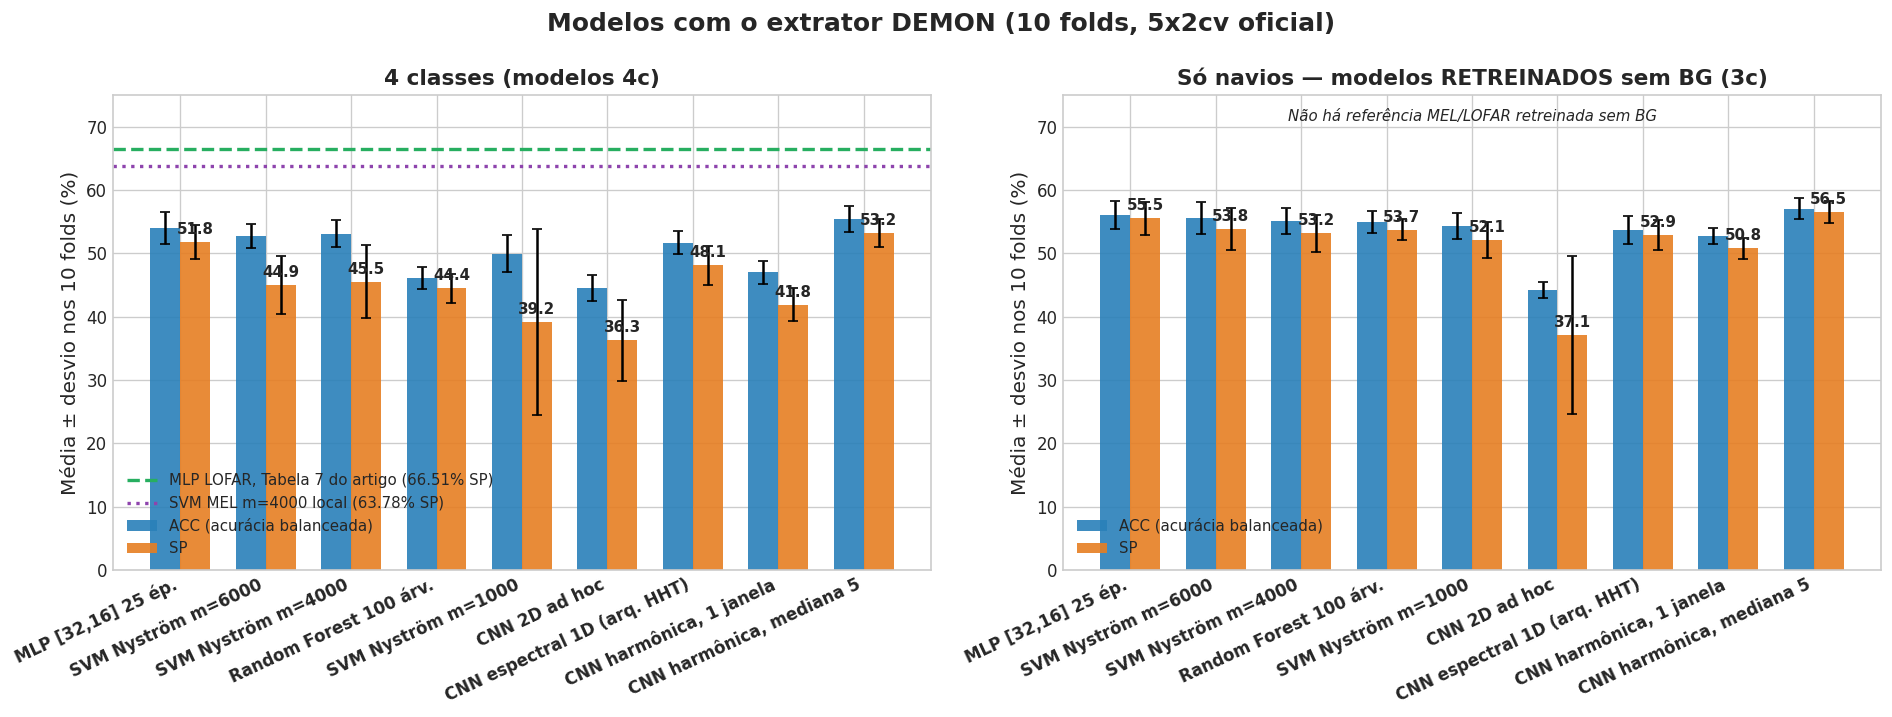

In [3]:
lbl4 = [f'DEMON | {l}' for l, _ in DEMON]
short = [l for l, _ in DEMON]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
x = np.arange(len(lbl4)); w = 0.35
for ax, S, title in [(ax1, S4, '4 classes (modelos 4c)'), (ax2, S3, 'Só navios — modelos RETREINADOS sem BG (3c)')]:
    acc = [S[l]['ACC'][0] for l in lbl4]; sp = [S[l]['SP'][0] for l in lbl4]
    ax.bar(x - w / 2, acc, w, yerr=[S[l]['ACC'][1] for l in lbl4], capsize=3, label='ACC (acurácia balanceada)', color='#2980b9', alpha=0.9)
    r = ax.bar(x + w / 2, sp, w, yerr=[S[l]['SP'][1] for l in lbl4], capsize=3, label='SP', color='#e67e22', alpha=0.9)
    for rect in r:
        ax.annotate(f'{rect.get_height():.1f}', xy=(rect.get_x() + rect.get_width() / 2, rect.get_height()),
                    xytext=(0, 3), textcoords='offset points', ha='center', va='bottom', fontsize=9, fontweight='bold')
    ax.set_xticks(x); ax.set_xticklabels(short, rotation=25, ha='right', fontweight='bold')
    ax.set_title(title, fontweight='bold'); ax.set_ylabel('Média ± desvio nos 10 folds (%)'); ax.set_ylim(0, 75)
mlp_lofar_art = R.ARTICLE_TABLE7[('MLP', 'LOFAR')]['SP'][0]
svm_mel = S4['SVM m=4000 | MEL']['SP'][0]
ax1.axhline(mlp_lofar_art, color='#27ae60', ls='--', lw=2, label=f'MLP LOFAR, Tabela 7 do artigo ({mlp_lofar_art:.2f}% SP)')
ax1.axhline(svm_mel, color='#8e44ad', ls=':', lw=2, label=f'SVM MEL m=4000 local ({svm_mel:.2f}% SP)')
ax1.legend(loc='lower left', fontsize=9)
ax2.legend(loc='lower left', fontsize=9)
ax2.text(0.5, 0.97, 'Não há referência MEL/LOFAR retreinada sem BG', transform=ax2.transAxes, ha='center', va='top', fontsize=9, style='italic')
plt.suptitle('Modelos com o extrator DEMON (10 folds, 5x2cv oficial)', fontsize=15, fontweight='bold', y=0.99)
plt.tight_layout()
plt.show()

## 3. Recall por Classe

Cada modelo extrai comportamentos distintos do envelope DEMON (recall médio nos 10 folds, modelos 4c):

,SMALL,MEDIUM,LARGE,BACKGROUND
"DEMON | MLP [32,16] 25 ép.",30.00,48.32,59.07,78.78
DEMON | SVM Nyström m=6000,11.85,47.72,79.21,72.14
DEMON | Random Forest 100 árv.,52.47,35.10,68.79,27.96
DEMON | CNN 2D ad hoc,8.71,41.34,60.33,67.55
"DEMON | CNN harmônica, mediana 5",33.93,38.86,61.12,87.55


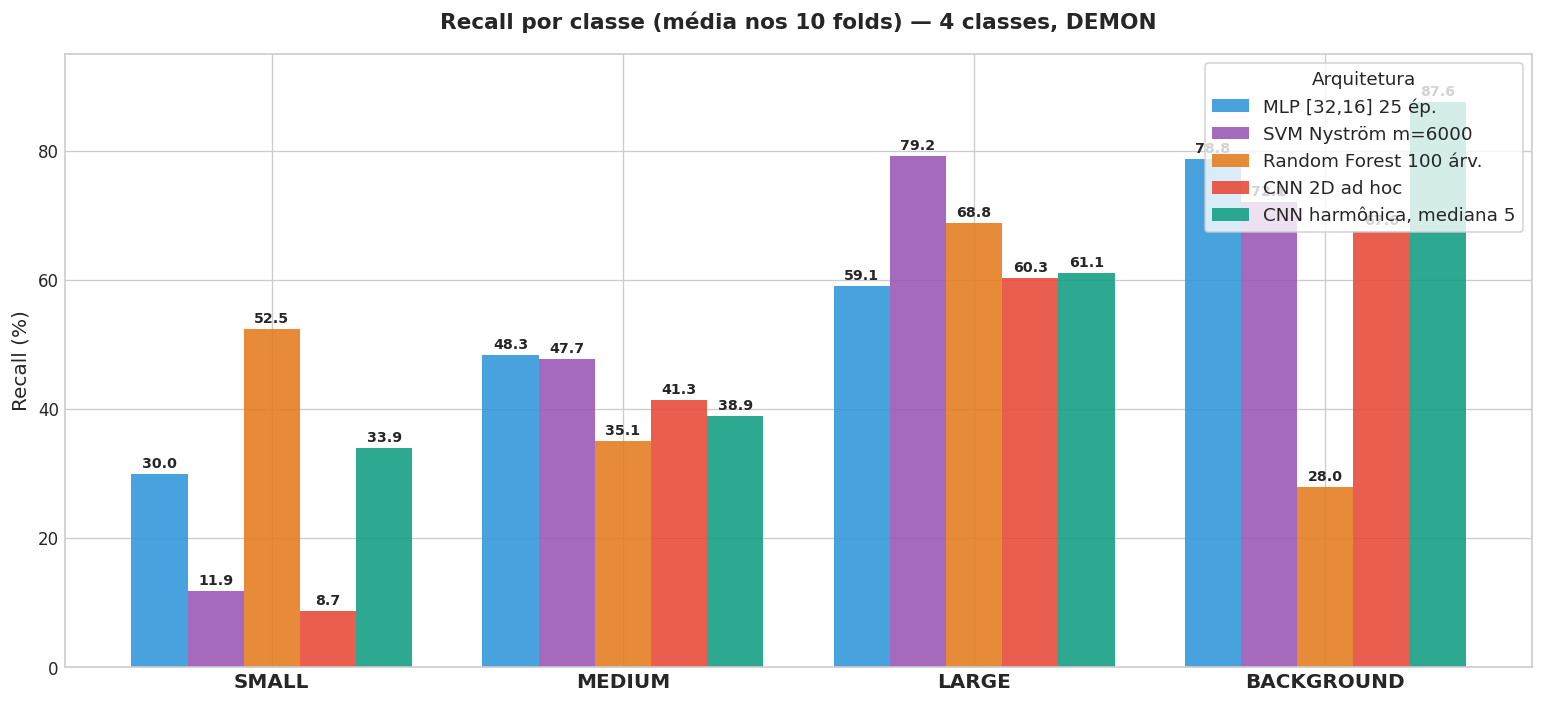

In [4]:
classes = ['SMALL', 'MEDIUM', 'LARGE', 'BACKGROUND']
subset = ['DEMON | MLP [32,16] 25 ép.', 'DEMON | SVM Nyström m=6000', 'DEMON | Random Forest 100 árv.', 'DEMON | CNN 2D ad hoc',
          'DEMON | CNN harmônica, mediana 5']
recalls_matrix = np.array([[S4[m][f'R_{c}'][0] for c in classes] for m in subset])
display(pd.DataFrame(recalls_matrix.round(2), index=subset, columns=classes))
fig, ax = plt.subplots(figsize=(13, 6))
x = np.arange(len(classes)); width = 0.8 / len(subset)
for i, (m, color) in enumerate(zip(subset, ['#3498db', '#9b59b6', '#e67e22', '#e74c3c', '#16a085'])):
    rects = ax.bar(x + (i - (len(subset) - 1) / 2) * width, recalls_matrix[i], width, label=m.replace('DEMON | ', ''), color=color, alpha=0.9)
    for rect in rects:
        ax.annotate(f'{rect.get_height():.1f}', xy=(rect.get_x() + rect.get_width() / 2, rect.get_height()),
                    xytext=(0, 2), textcoords='offset points', ha='center', va='bottom', fontsize=8.5, fontweight='bold')
ax.set_title('Recall por classe (média nos 10 folds) — 4 classes, DEMON', fontweight='bold', pad=15)
ax.set_xticks(x); ax.set_xticklabels(classes, fontsize=12, fontweight='bold')
ax.set_ylabel('Recall (%)'); ax.set_ylim(0, 95)
ax.legend(title='Arquitetura', loc='upper right', frameon=True)
plt.tight_layout()
plt.show()

### Principais Fenômenos Observados (valores calculados acima e nas matrizes da seção 4):
1. **Random Forest e SMALL (52,47%):** o RF tem o maior recall de SMALL entre os modelos DEMON 4c. *Hipótese:* cortes ortogonais em bins isolados não são diluídos pelos demais bins, como ocorre num produto escalar global.
2. **O colapso do RF em BACKGROUND (27,96%):** o RF classifica **48,6%** das instâncias de fundo como SMALL (matriz acumulada). Parte do recall de SMALL do RF vem, portanto, de um viés para SMALL, não de discriminação.
3. **O equilíbrio do MLP (51,76% SP):** o MLP mantém **78,78% de BACKGROUND** e envia 22,5% dos SMALL para LARGE (contra 42,4% no SVM m=6000). A vantagem de SP do MLP sobre o SVM m=6000 é **não** significativa (F = 4,18, p = 0,064); sobre o RF é significativa (F = 4,87, p = 0,047).

## 4. Matrizes de Confusão Acumuladas nos 10 Folds ($5\times2$cv)

### 4.1 Problema de 4 Classes (SMALL, MEDIUM, LARGE, BACKGROUND)
Matrizes por arquivo, **acumuladas** nas 10 dobras (n = 6.390 instâncias arquivo × fold; cada arquivo aparece em média 3,75 vezes no teste) e normalizadas por linha. A diagonal acumulada difere ligeiramente do recall médio por fold da tabela.

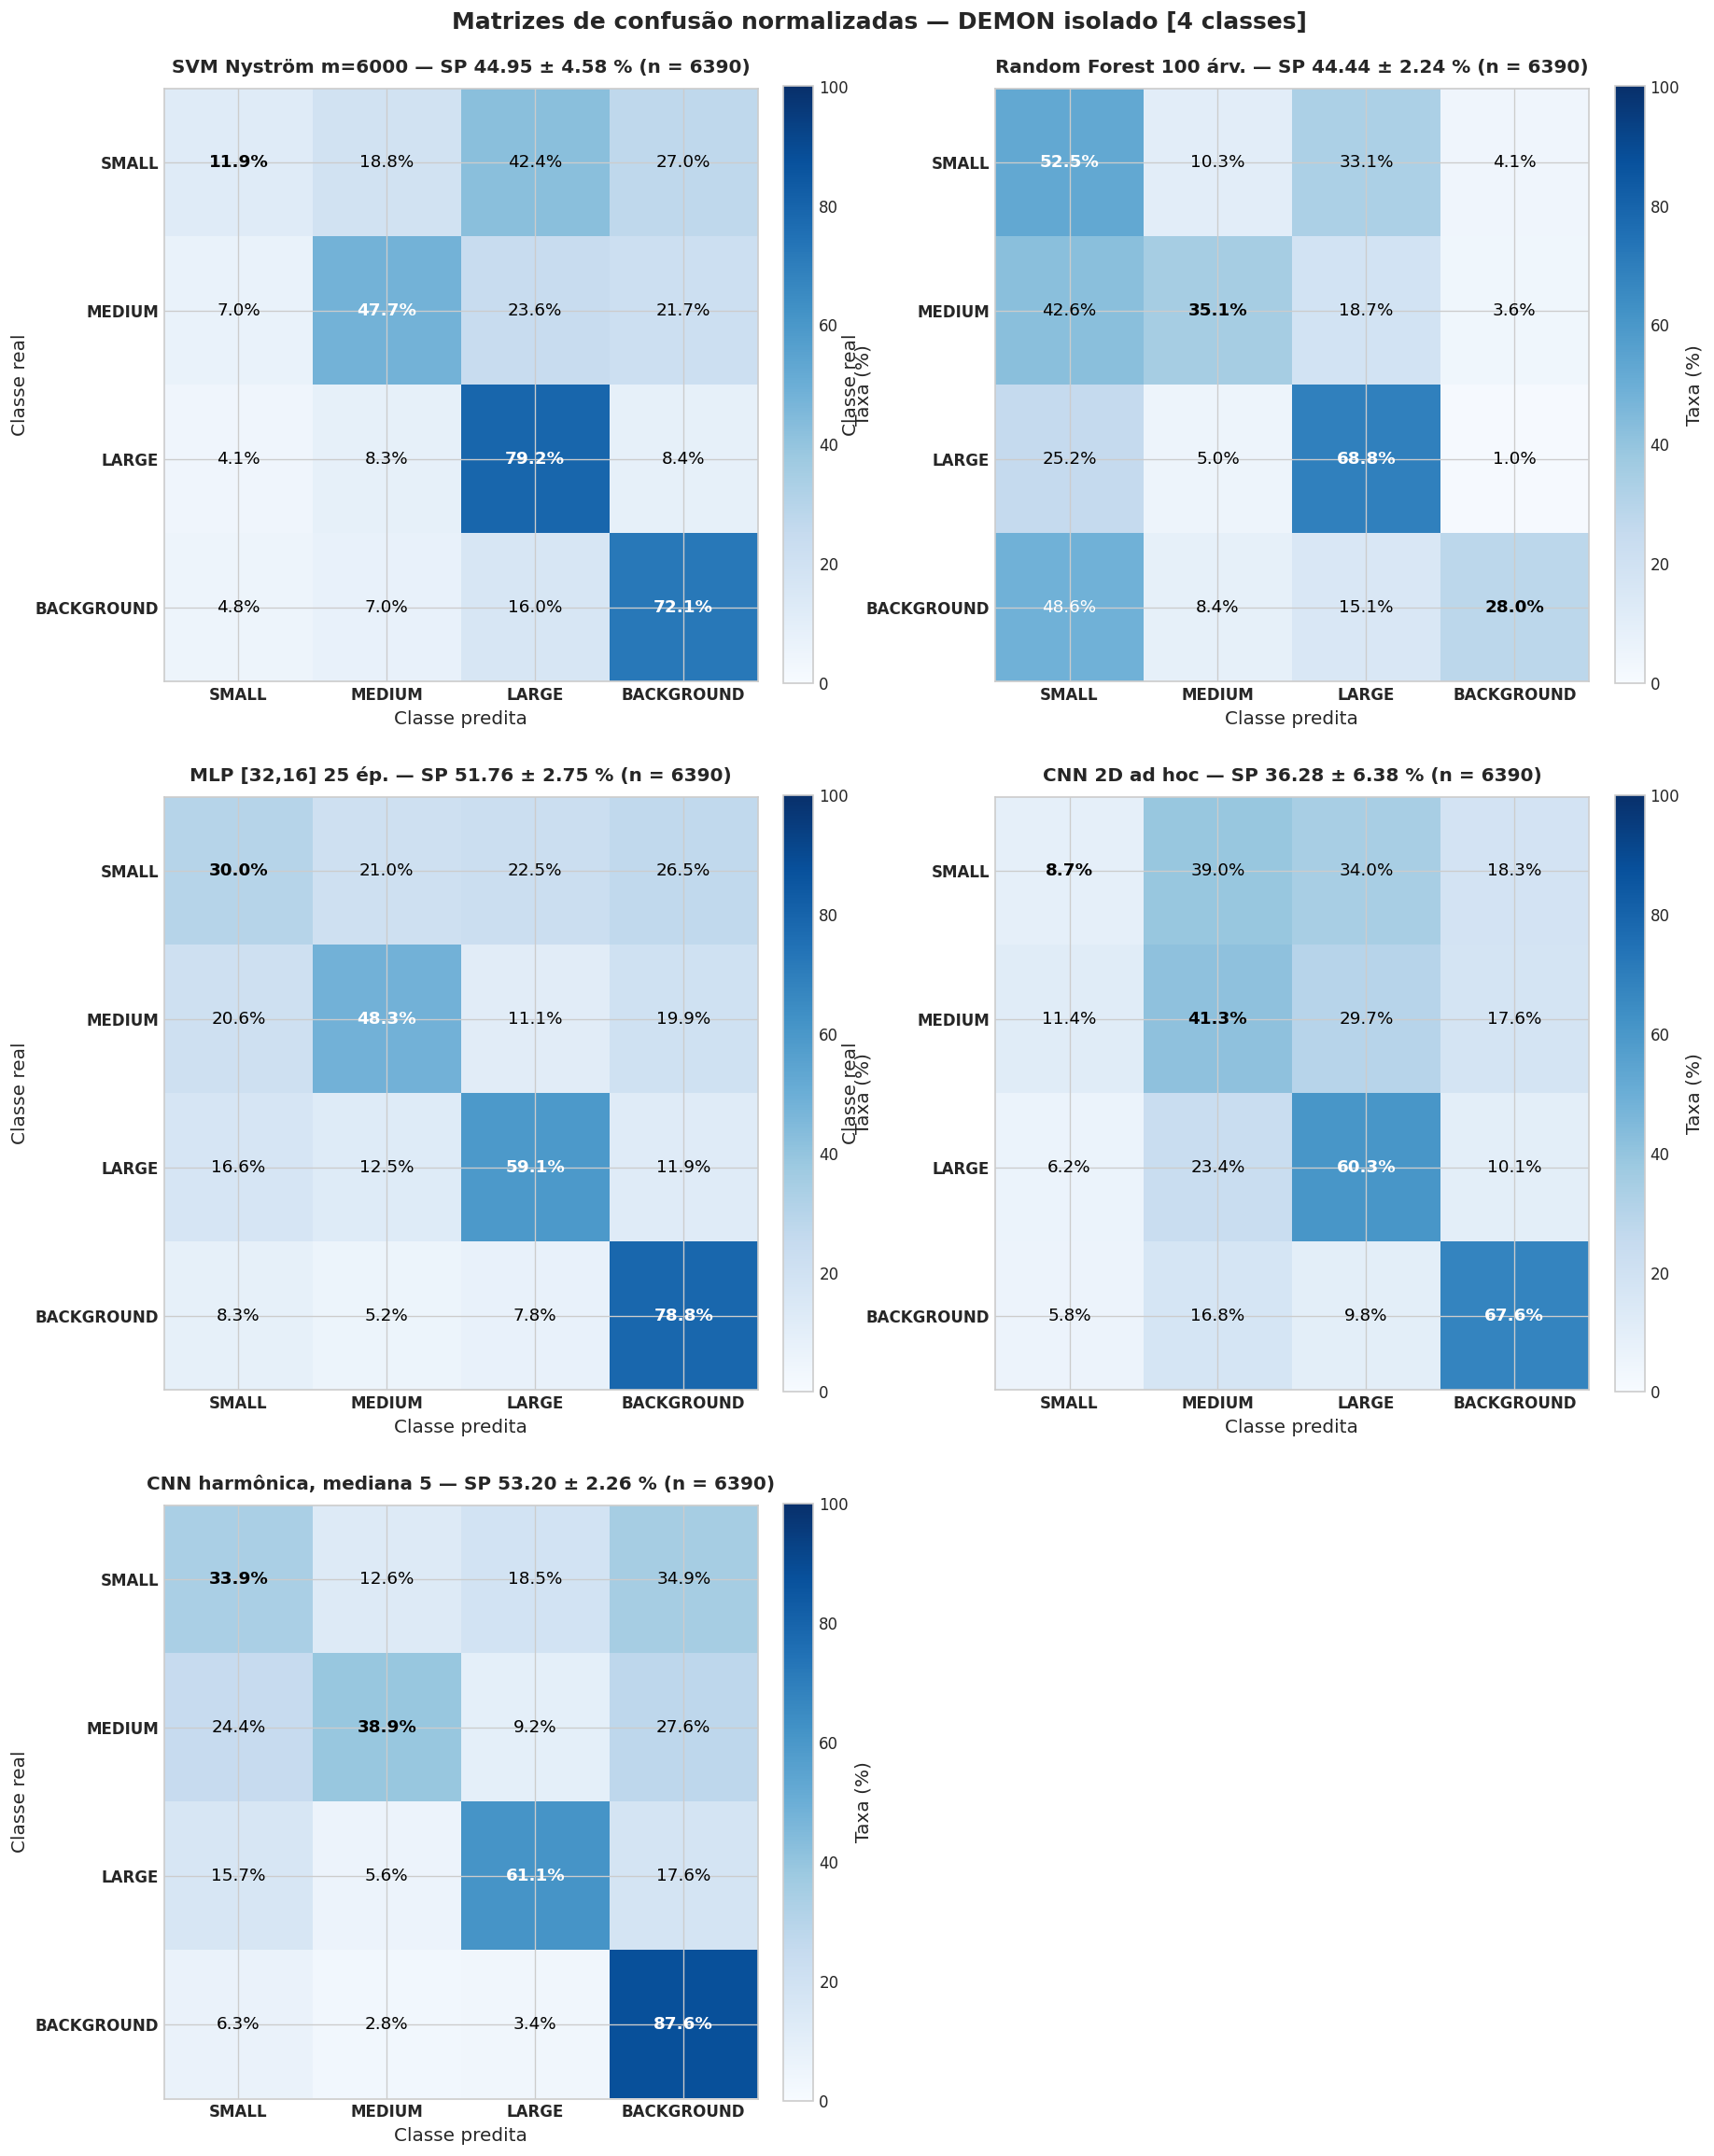

In [5]:
CLS = ['SMALL', 'MEDIUM', 'LARGE', 'BACKGROUND']


def confusion(exp):
    """Matriz de confusão por arquivo, ACUMULADA nas 10 dobras (instâncias arquivo x fold), normalizada por linha (%)."""
    df = pd.concat(R.file_predictions(exp).values(), ignore_index=True)
    rows = sorted(df.Target.unique())
    cols = sorted(set(rows) | set(df.Prediction.unique()))
    cm = pd.crosstab(df.Target, df.Prediction).reindex(index=rows, columns=cols, fill_value=0)
    cmn = 100 * cm.div(cm.sum(axis=1), axis=0)
    cmn.index = [CLS[i] for i in rows]; cmn.columns = [CLS[i] for i in cols]
    return cmn, int(cm.values.sum())


CM_MODELS = [('SVM Nyström m=6000', 'svm_nystroem_6000_demon_C2.0_elasticnet_l1r0.15_it1000'),
             ('Random Forest 100 árv.', 'rf_demon_n100_balanced'),
             ('MLP [32,16] 25 ép.', 'mlp_demon_h32-16_e25'),
             ('CNN 2D ad hoc', 'cnn2d_demon_w32_b32_e20'),
             ('CNN harmônica, mediana 5', 'hcnn_demon_tpsw_med5_e60p8')]
CM4 = {l: confusion(e + '_4c') for l, e in CM_MODELS}
CM3 = {l: confusion(e + '_3c') for l, e in CM_MODELS}
N_FILES = len(set().union(*[set(d.File) for d in R.file_predictions(CM_MODELS[0][1] + '_4c').values()]))


def plot_cms(CMS, S, prefix, cmap, suptitle):
    nl = (len(CMS) + 1) // 2
    fig, axes = plt.subplots(nl, 2, figsize=(15, 6.5 * nl))
    for ax in axes.flatten()[len(CMS):]:
        ax.axis('off')
    for ax, (l, (cm, n)) in zip(axes.flatten(), CMS.items()):
        sp = S[f'DEMON | {l}']['SP']
        im = ax.imshow(cm.values, cmap=cmap, vmin=0, vmax=100)
        ax.set_title(f'{l} — SP {sp[0]:.2f} ± {sp[1]:.2f} % (n = {n})', fontsize=12, fontweight='bold', pad=10)
        ax.set_xticks(range(cm.shape[1])); ax.set_xticklabels(cm.columns, fontweight='bold')
        ax.set_yticks(range(cm.shape[0])); ax.set_yticklabels(cm.index, fontweight='bold')
        ax.set_xlabel('Classe predita'); ax.set_ylabel('Classe real')
        for i in range(cm.shape[0]):
            for j in range(cm.shape[1]):
                v = cm.values[i, j]
                ax.text(j, i, f'{v:.1f}%', ha='center', va='center', color='white' if v > 45 else 'black',
                        fontweight='bold' if i == j else 'normal')
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04).set_label('Taxa (%)')
    plt.suptitle(suptitle, fontsize=15, fontweight='bold', y=0.99)
    plt.tight_layout()
    plt.show()

plot_cms(CM4, S4, 'DEMON', 'Blues', 'Matrizes de confusão normalizadas — DEMON isolado [4 classes]')

### 4.2 Modelos Retreinados sem BACKGROUND (3c: SMALL, MEDIUM, LARGE)

Modelos **retreinados** só com as três classes de navio (experimentos `*_3c`). Isto mede a capacidade do envelope DEMON de separar os portes quando o fundo é removido do treino **e** do teste:

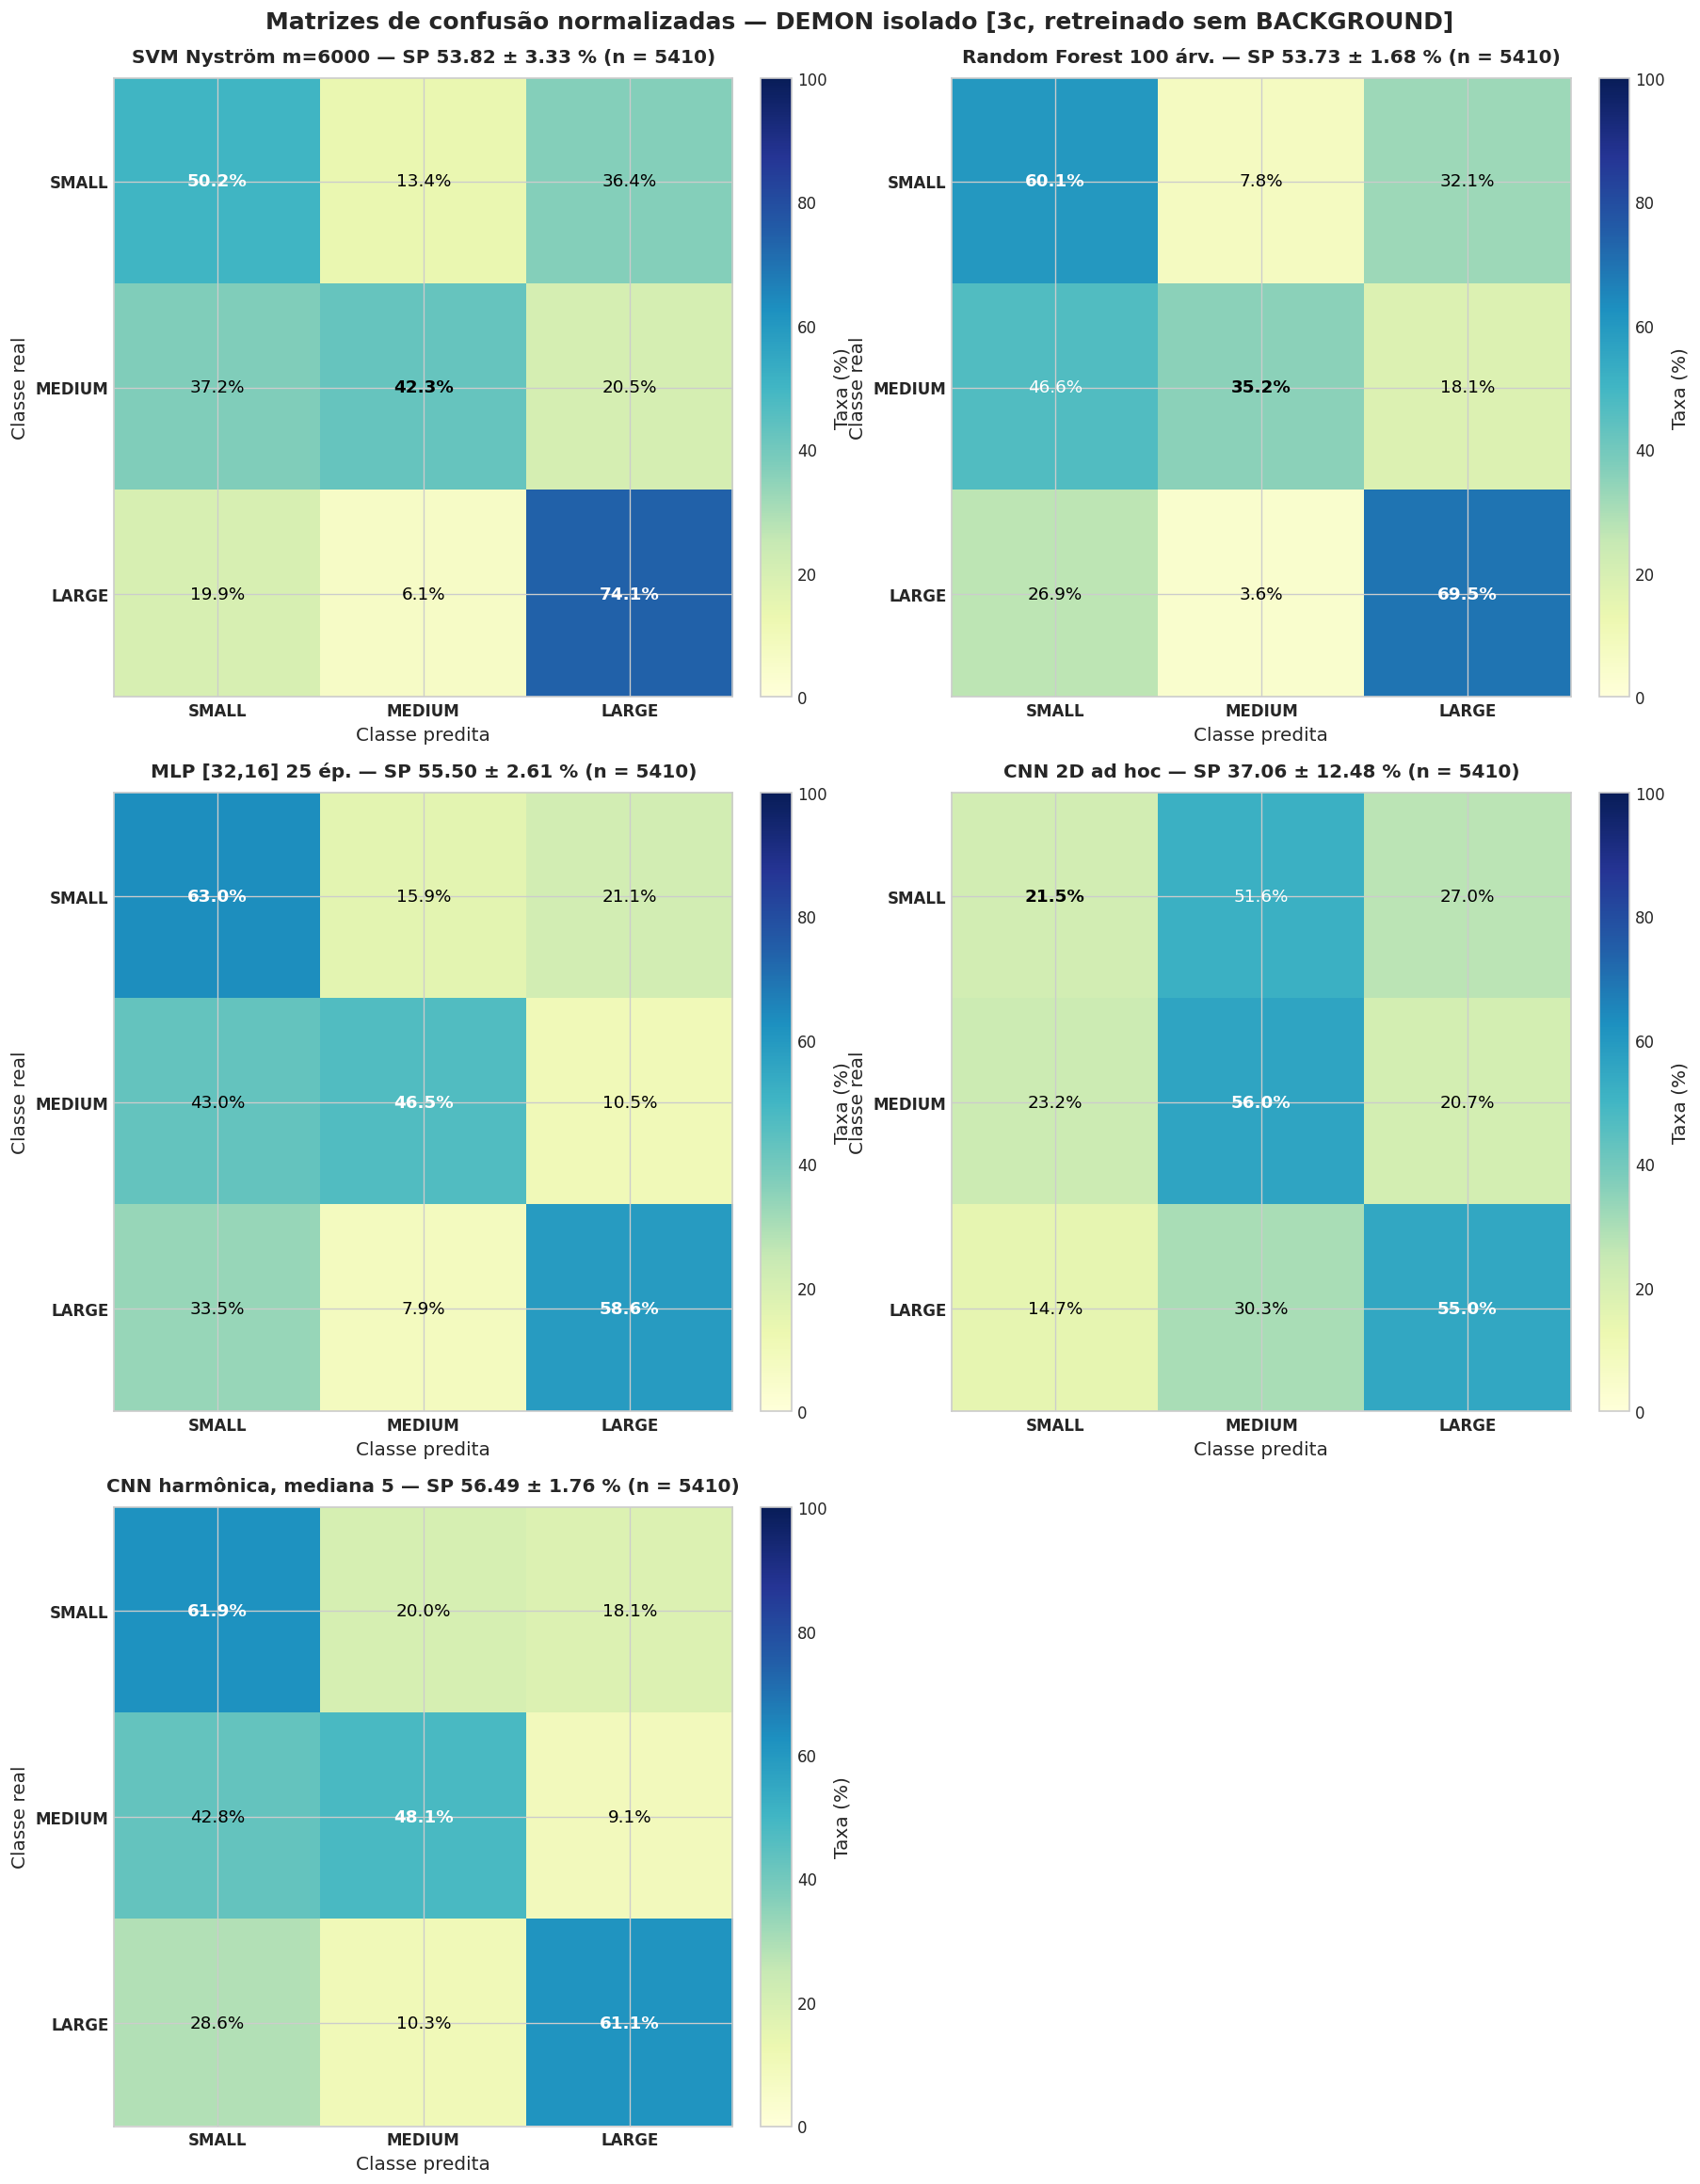

In [6]:
plot_cms(CM3, S3, 'DEMON', 'YlGnBu', 'Matrizes de confusão normalizadas — DEMON isolado [3c, retreinado sem BACKGROUND]')

### Análise Comparativa do Comportamento em 3 Classes (3c):
1. **SMALL sobe quando o BACKGROUND é retirado do problema:**
   - No 4c, a fração de SMALL classificada como BACKGROUND é 26,5% (MLP), 27,0% (SVM m=6000), 4,1% (RF) e 18,3% (CNN).
   - Nos modelos 3c, o recall de SMALL é 62,98% (MLP; 30,00% no 4c), 60,06% (RF; 52,47% no 4c) e 50,22% (SVM m=6000; 11,85% no 4c). É outro problema (3 classes), não um ganho do DEMON comparável aos modelos 4c.
2. **A confusão SMALL → LARGE persiste:**
   - No 3c, 21,1% (MLP), 36,4% (SVM m=6000) e 32,1% (RF) dos SMALL ainda são preditos como LARGE.
   - *Hipótese física (não testada aqui):* em baixa velocidade, lanchas produzem pouca cavitação na banda de 1–2 kHz e o envelope passa a ser dominado por modulações lentas, parecidas com as de navios grandes.
3. **MEDIUM é atraído para as duas pontas:** no 3c, 37,2% a 46,6% dos MEDIUM vão para SMALL e 10,5% a 20,5% para LARGE (MLP, SVM m=6000 e RF).

## 5. Testes Estatísticos (F-test 5x2cv)

Toda afirmação de "supera" abaixo depende deste teste (Alpaydin, 1999; o mesmo usado no artigo):

In [7]:
# F-test 5x2cv combinado (Alpaydin), como no artigo. Modelos 4c; recall de SMALL é idêntico em 4c e 4c_sem_bg.
PAIRS = [
    ('DEMON | MLP [32,16] 25 ép.', 'MLP (≈ artigo) | LOFAR', 'SP'),
    ('DEMON | MLP [32,16] 25 ép.', 'SVM m=4000 | MEL', 'SP'),
    ('DEMON | MLP [32,16] 25 ép.', 'DEMON | SVM Nyström m=6000', 'SP'),
    ('DEMON | MLP [32,16] 25 ép.', 'DEMON | Random Forest 100 árv.', 'SP'),
    ('DEMON | MLP [32,16] 25 ép.', 'DEMON | MLP [32,16] 35 ép. (grade da fusão, NB12)', 'SP'),
    ('DEMON | Random Forest 100 árv.', 'SVM m=6000 | LOFAR', 'R_SMALL'),
    ('DEMON | Random Forest 100 árv.', 'SVM m=4000 PCA64 | LOFAR', 'R_SMALL'),
    ('DEMON | Random Forest 100 árv.', 'MLP (≈ artigo) | LOFAR', 'R_SMALL'),
    ('DEMON | Random Forest 100 árv.', 'SVM m=4000 | MEL', 'R_SMALL'),
    ('DEMON | CNN harmônica, mediana 5', 'DEMON | MLP [32,16] 25 ép.', 'SP'),
    ('DEMON | CNN harmônica, mediana 5', 'DEMON | MLP [32,16] 35 ép. (grade da fusão, NB12)', 'SP'),
    ('DEMON | CNN harmônica, mediana 5', 'DEMON | Random Forest 100 árv.', 'SP'),
    ('DEMON | CNN harmônica, mediana 5', 'DEMON | CNN 2D ad hoc', 'SP'),
    ('DEMON | CNN harmônica, mediana 5', 'DEMON | CNN harmônica, 1 janela', 'SP'),
    ('DEMON | CNN harmônica, mediana 5', 'DEMON | CNN espectral 1D (arq. HHT)', 'SP'),
    ('DEMON | CNN harmônica, mediana 5', 'DEMON | Random Forest 100 árv.', 'R_SMALL'),
]
rows = []
for a, b, met in PAIRS:
    F, p = R.f_test_5x2(E4[a], E4[b], metric=met)
    rows.append({'A': a, 'B': b, 'métrica': met, 'média A': round(S4[a][met][0], 2), 'média B': round(S4[b][met][0], 2),
                 'F': round(F, 2), 'p': round(p, 4), 'p < 0,05': p < 0.05})
df_tests = pd.DataFrame(rows)
display(df_tests)

,A,B,métrica,média A,média B,F,p,"p < 0,05"
0,"DEMON | MLP [32,16] 25 ép.",MLP (≈ artigo) | LOFAR,SP,51.76,66.24,23.23,0.0014,True
1,"DEMON | MLP [32,16] 25 ép.",SVM m=4000 | MEL,SP,51.76,63.78,110.48,0.0000,True
2,"DEMON | MLP [32,16] 25 ép.",DEMON | SVM Nyström m=6000,SP,51.76,44.95,4.18,0.0640,False
3,"DEMON | MLP [32,16] 25 ép.",DEMON | Random Forest 100 árv.,SP,51.76,44.44,4.87,0.0472,True
4,"DEMON | MLP [32,16] 25 ép.","DEMON | MLP [32,16] 35 ép. (grade da fusão, NB12)",SP,51.76,53.09,1.15,0.4640,False
5,DEMON | Random Forest 100 árv.,SVM m=6000 | LOFAR,R_SMALL,52.47,38.15,2.05,0.2213,False
6,DEMON | Random Forest 100 árv.,SVM m=4000 PCA64 | LOFAR,R_SMALL,52.47,47.64,0.76,0.6708,False
7,DEMON | Random Forest 100 árv.,MLP (≈ artigo) | LOFAR,R_SMALL,52.47,46.35,0.72,0.6904,False
8,DEMON | Random Forest 100 árv.,SVM m=4000 | MEL,R_SMALL,52.47,50.73,0.98,0.5435,False
9,"DEMON | CNN harmônica, mediana 5","DEMON | MLP [32,16] 25 ép.",SP,53.20,51.76,1.89,0.2508,False


## 6. Diagnóstico Científico e Conclusões

### 6.1 A CNN 2D ad hoc colapsou no DEMON
* SP 4c = **36,28 ± 6,38%** (folds: 45,3, 36,4, 32,7, 28,9, 26,7, 40,2, 33,9, 45,6, 41,8, 31,2), recall SMALL 8,71%; no 3c, SP = 37,06 ± 12,48% (folds: 43,2, 38,6, 43,0, 40,9, 0,0, 39,4, 41,7, 39,2, 40,1, 44,3). Com esse desempenho e essa variância, o modelo deve ser tratado como **colapsado** (20 épocas sem early stopping, conforme `config.json`), e não como evidência sobre a adequação de convoluções ao DEMON.
* *Hipótese (não testada):* o espectro DEMON é formado por raias finas e esparsas, e convoluções com pooling tenderiam a suavizá-las. A seção 6.2 mostra que CNNs com outro desenho não colapsam no mesmo dado.

### 6.2 Duas CNNs novas no DEMON
Treino comum: uma amostra por janela de 5,12 s, validação interna com 15% das gravações de treino (separadas por gravação), early stopping, semente fixa por fold, voto majoritário por gravação. As configurações foram fixadas antes de rodar.

| Modelo | SP 4c | SP 3c (retreinado) | Recall SMALL 4c | Recall BACKGROUND 4c |
| :--- | :---: | :---: | :---: | :---: |
| CNN espectral 1D (arquitetura HHT, sem mudanças) | 48,07 ± 3,02 | 52,88 ± 2,41 | 22,19% | 84,29% |
| CNN harmônica, 1 janela | 41,84 ± 2,62 | 50,76 ± 1,64 | 14,94% | 93,06% |
| CNN harmônica, mediana de 5 janelas | 53,20 ± 2,26 | 56,49 ± 1,76 | 33,93% | 87,55% |
| MLP [32,16] 25 ép. (referência) | 51,76 ± 2,75 | 55,50 ± 2,61 | 30,00% | 78,78% |
| BiGRU + atenção (Notebook 25, referência) | 55,54 ± 1,41 | 56,79 ± 1,11 | 40,45% | 64,90% |

* **A CNN harmônica com mediana de 5 janelas não colapsa e empata com os melhores modelos DEMON:** contra o MLP 25 ép. F = 1,89, p = 0,251; contra o MLP 35 ép. F = 2,47, p = 0,165; contra a BiGRU p = 0,551 (4c) e p = 0,404 (3c); contra o MLP 25 ép. em 3c p = 0,752. Supera significativamente o RF (F = 7,27, p = 0,020) e a CNN 2D ad hoc (F = 9,20, p = 0,012).
* **A mediana temporal é decisiva:** sem ela (1 janela) o SP cai para 41,84 ± 2,62 (F = 28,79, p < 0,001) e o modelo prevê BACKGROUND para quase tudo (recall BACKGROUND 93,06%, SMALL 14,94%). *Hipótese (não testada):* numa janela isolada o TPSW realça ruído tanto quanto raias; a mediana de 5 janelas deixa só as raias estáveis, como as do eixo da hélice.
* **A arquitetura da HHT não serve ao DEMON sem adaptação:** a CNN espectral fica em 48,07 ± 3,02 (contra a CNN harmônica com mediana: F = 4,08, p = 0,067). Ela foi desenhada e configurada no HHT, então a comparação a desfavorece.
* **SMALL continua sendo o ponto fraco:** recall de SMALL da CNN harmônica 33,93%, abaixo do RF DEMON (52,47%; F = 2,17, p = 0,203), cujo recall de SMALL vem acompanhado de um viés para SMALL (seção 3).
* **Limites:** não houve ablação; não dá para separar o efeito do TPSW, do empilhamento harmônico e da mediana. Os parâmetros do TPSW (n = 16, g = 3, α = 2) e os harmônicos foram fixados a priori, sem ajuste.

### 6.3 O teto do DEMON isolado
* O melhor SP 4c entre os modelos DEMON desta tabela é **53,20 ± 2,26%** (CNN harmônica, mediana 5); a melhor configuração DEMON em disco entre esses modelos é CNN harmônica, mediana 5 com 53,20 ± 2,26%. Fora desses modelos, a BiGRU com atenção sobre sequências DEMON (`bigru_att_demon_h64_s15-5_e20_4c`, Notebook 25) chega a 55,54 ± 1,41%.
* Isso fica **13,3 p.p.** abaixo da MLP LOFAR da Tabela 7 do artigo (66,51 ± 1,39%), 13,0 p.p. abaixo da MLP LOFAR local (66,24 ± 1,78%; F-test F = 23,23, p = 0,001) e 10,6 p.p. abaixo do SVM MEL m=4000 (63,78 ± 1,14%; F-test F = 110,48, p < 0,001).
* Como a diferença se repete em todas as famílias de modelos, os dados **sugerem** que a limitação está na representação: o DEMON descarta o espectro direto (raias de máquinas, energia de banda larga) e retém só a envoltória de 1–2 kHz entre 0,39 e 25 Hz.

### 6.4 O papel do DEMON na arquitetura IARA
1. **Não usar monoliticamente:** o DEMON não deve ser o classificador primário de 4 classes.
2. **Fusão Multimodal (`MEL + DEMON`):** avaliada no Notebook 12.
3. **Especialista entre embarcações — o que os dados permitem dizer:**
   - Comparação válida em SMALL (modelos 4c, mesmo modo de avaliação): RF DEMON 52,47% contra 38,15% (SVM LOFAR m=6000; F = 2,05, p = 0,221), 47,64% (SVM LOFAR m=4000 PCA64; F = 0,76, p = 0,671), 46,35% (MLP LOFAR local; F = 0,72, p = 0,690) e 50,73% (SVM MEL m=4000; F = 0,98, p = 0,543). Nenhuma dessas diferenças é significativa no F-test 5x2cv (p ≥ 0,05): o recall de SMALL do RF DEMON é **equivalente** ao das referências, dentro da variação entre folds, e o recall de SMALL do RF vem junto com 48,6% do fundo classificado como SMALL (seção 3).
   - Uma versão anterior afirmava que o DEMON "supera com folga o LOFAR" em SMALL, comparando o recall de modelos DEMON **retreinados sem BG** (50,22% SVM m=6000, 60,06% RF) com o recall de um LOFAR **4c**. Essa comparação mistura problemas diferentes e foi retirada. Para sustentar o DEMON como especialista seria preciso retreinar também MEL/LOFAR sem BG e aplicar o F-test.